# Measuring and Mitigating Group Fairness with Fairlearn

This tutorial evaluates a binary classifier across a synthetic sensitive group and applies `ThresholdOptimizer` with demographic-parity constraints. The fixture makes group disparities visible without using personal data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate
from fairlearn.postprocessing import ThresholdOptimizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_SEED = 800
OUTPUT_DIR = Path('generated/responsible-ai-800')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)
rows = 1800
sensitive = rng.choice(['Group A', 'Group B'], size=rows, p=[0.55, 0.45])
experience = rng.normal(5, 2, rows)
assessment = rng.normal(0, 1, rows)
training = rng.binomial(1, np.where(sensitive == 'Group A', 0.62, 0.42))
logit = -0.8 + 0.35 * experience + 1.1 * assessment + 0.7 * training - 0.45 * (sensitive == 'Group B')
probability = 1 / (1 + np.exp(-logit))
target = rng.binomial(1, probability)
features = pd.DataFrame({'experience': experience, 'assessment': assessment, 'training': training})
X_train, X_test, y_train, y_test, A_train, A_test = train_test_split(
    features,
    target,
    sensitive,
    test_size=0.30,
    stratify=target,
    random_state=RANDOM_SEED,
)
print(f'train rows: {len(X_train)}; holdout rows: {len(X_test)}')

train rows: 1260; holdout rows: 540


## 1. Train and Audit a Baseline

Sensitive group membership is not included as a model input, but disparities can still arise through the label-generating process and correlated features.

In [2]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=RANDOM_SEED),
)
model.fit(X_train, y_train)
baseline_predictions = model.predict(X_test)

metrics = {
    'accuracy': accuracy_score,
    'selection_rate': selection_rate,
    'true_positive_rate': true_positive_rate,
}
baseline_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=baseline_predictions,
    sensitive_features=A_test,
)
print('baseline by group:')
print(baseline_frame.by_group.round(3).to_string())
print()
print('baseline differences:')
print(baseline_frame.difference().round(3).to_string())

baseline by group:
                     accuracy  selection_rate  true_positive_rate
sensitive_feature_0                                              
Group A                 0.786           0.845               0.921
Group B                 0.719           0.779               0.897

baseline differences:
accuracy              0.067
selection_rate        0.066
true_positive_rate    0.024


## 2. Apply a Demographic-Parity Constraint

`ThresholdOptimizer` learns group-specific randomized thresholds from training data. This post-processing choice requires sensitive features at prediction time and can trade accuracy or other fairness criteria for selection-rate parity.

In [3]:
mitigator = ThresholdOptimizer(
    estimator=model,
    constraints='demographic_parity',
    objective='accuracy_score',
    predict_method='predict_proba',
    prefit=True,
)
mitigator.fit(X_train, y_train, sensitive_features=A_train)
mitigated_predictions = mitigator.predict(
    X_test,
    sensitive_features=A_test,
    random_state=RANDOM_SEED,
)
mitigated_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=mitigated_predictions,
    sensitive_features=A_test,
)
print('mitigated by group:')
print(mitigated_frame.by_group.round(3).to_string())
print()
print('mitigated differences:')
print(mitigated_frame.difference().round(3).to_string())

mitigated by group:
                     accuracy  selection_rate  true_positive_rate
sensitive_feature_0                                              
Group A                 0.789           0.854               0.930
Group B                 0.700           0.871               0.956

mitigated differences:
accuracy              0.089
selection_rate        0.016
true_positive_rate    0.026


## 3. Compare Group Metrics Before and After Mitigation

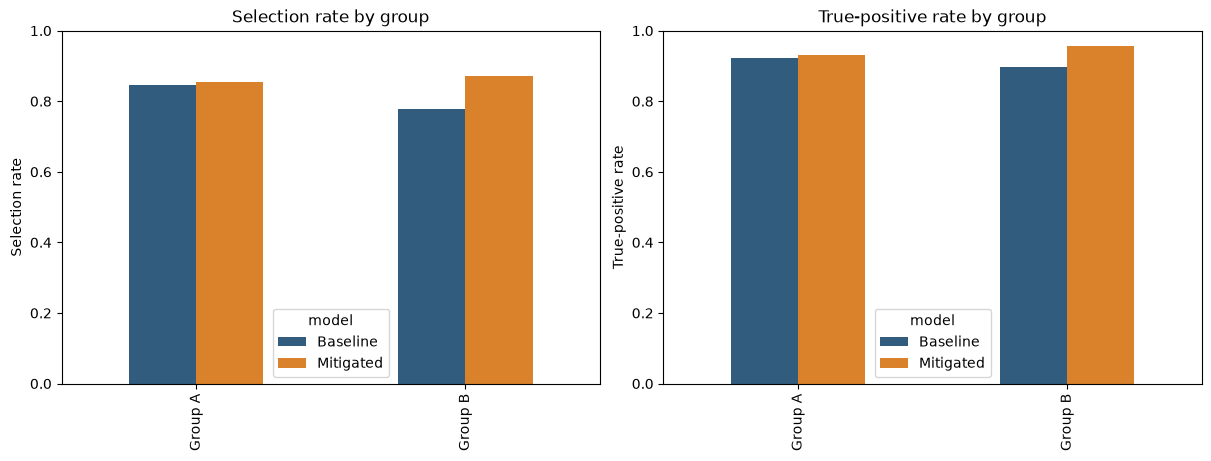

saved: generated\responsible-ai-800\fairlearn-group-metrics.png


In [4]:
comparison = pd.concat(
    {
        'Baseline': baseline_frame.by_group,
        'Mitigated': mitigated_frame.by_group,
    },
    names=['model', 'group'],
)
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
comparison['selection_rate'].unstack('model').plot.bar(color=['#315c7d', '#d9822b'], ax=axes[0])
axes[0].set(title='Selection rate by group', ylabel='Selection rate', xlabel=None, ylim=(0, 1))
comparison['true_positive_rate'].unstack('model').plot.bar(color=['#315c7d', '#d9822b'], ax=axes[1])
axes[1].set(title='True-positive rate by group', ylabel='True-positive rate', xlabel=None, ylim=(0, 1))
figure_path = OUTPUT_DIR / 'fairlearn-group-metrics.png'
figure.savefig(figure_path, dpi=170, bbox_inches='tight')
plt.show()
print(f'saved: {figure_path}')

## 4. Responsible-Use Limits

No fairness metric is universally correct. Demographic parity may conflict with equalized odds, calibration, legal requirements, or the purpose of a decision process. Sensitive attributes, labels, affected groups, measurement error, and potential harms require stakeholder and legal review before deployment.